# Week 10 — Beyond the Basics: Structured Output, `create_agent`, Middleware & Outside MCP Servers

So far you have built agents with `smolagents`, hand-written LangGraph graphs and your own MCP servers. This short notebook shows **modern building blocks that the course has not covered yet**. Every section is a quick demo (a few cells) — enough to know what exists and when to reach for it, not a deep dive.

| # | Topic | One-line idea |
|---|---|---|
| 1 | Structured output | `model.with_structured_output(Schema)` makes an LLM return a typed object (`Literal` labels, `bool` flags) instead of free text |
| 2 | `create_agent` | One call builds the whole tool-calling agent loop (replaces `create_react_agent` and hand-built graphs) |
| 3 | Memory | A *checkpointer* + `thread_id` gives an agent short-term memory |
| 4 | Middleware | Hooks around model and tool calls: personalization, logging, PII redaction, summarization, fallbacks |
| 5 | Outside MCP servers | Plug *existing* MCP servers (remote or local) into your agent — no server code to write |
| 6 | Putting it together | One agent that combines MCP tools, middleware and memory |

Human-in-the-loop (pausing an agent for approval) has its own notebook: `W10_Human_in_the_Loop.ipynb`.

**Prerequisites:** weeks 7–9 (LangGraph agents, MCP basics, guardrails).
**You need:** an API key stored in a `.env` file (section 0 shows how) and Node.js (`npx`) for one local MCP example (already installed on Google Colab).

## Run this first on Google Colab

On your own computer the course environment already has everything, so this cell does nothing. On **Google Colab** it installs the packages this notebook needs (Colab already includes Node.js for the `npx` example). If Colab asks you to restart the runtime afterwards, do it once and continue from the next cell.

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules  # True only on Google Colab

if IN_COLAB:
    %pip install -q -U "langchain>=1.1,<2" langchain-openai langchain-mcp-adapters langgraph python-dotenv
else:
    print("Not on Colab: using the packages already installed in your environment.")

Not on Colab: using the packages already installed in your environment.


## 0. Setup: API keys with a `.env` file

Earlier notebooks read the key from `config.json`. The more common, safer habit in real projects is a **`.env` file**.

**Why not paste the key into the notebook?** Notebooks get shared, emailed and pushed to GitHub, and a key that leaks can be used (and billed) by anyone. A `.env` file keeps secrets *outside* your code.

**What is a `.env` file?** A plain-text file named exactly `.env` (note the leading dot) with one `NAME=value` per line:

```text
OPENAI_API_KEY=your-key-here
OPENAI_BASE_URL=https://your-course-endpoint/v1
```

Rules: no spaces around `=`, and usually no quotes. `OPENAI_BASE_URL` is only needed when your instructor gives you a custom endpoint (as in this course); with a regular OpenAI key, leave it out.

**How to use it**

1. **Create** the file in the project root (the folder that contains `pyproject.toml`). In a terminal: `cp .env.example .env`, then open `.env` and fill in your values. The file starts with a dot, so it is hidden in some file browsers (`ls -a` shows it).
2. **Never commit it.** This repository's `.gitignore` already lists `.env`; share the template `.env.example` instead (it has no real secrets).
3. **Load it** with the `python-dotenv` package: `load_dotenv()` copies each line into `os.environ`. `find_dotenv()` looks in the current folder and then upward, so the notebook finds the `.env` in the project root.
4. **Use it.** `langchain-openai` reads `OPENAI_API_KEY` and `OPENAI_BASE_URL` from the environment by itself, so you never pass the key to the model explicitly.

**On Google Colab** there is no project folder to keep a `.env` in. Use Colab **Secrets** instead: click the key icon in the left sidebar, add a secret named `OPENAI_API_KEY` (and `OPENAI_BASE_URL` if needed), and switch on *Notebook access*. The next cell reads them for you.

In [2]:
import asyncio, json, os, re, shutil, tempfile
from dataclasses import dataclass
from pathlib import Path
from typing import Literal

from dotenv import find_dotenv, load_dotenv
from IPython.display import Image, display
from langchain_core.runnables.graph_mermaid import draw_mermaid_png
from pydantic import BaseModel, Field
from langchain.chat_models import init_chat_model
from langchain.agents import create_agent, AgentState
from langchain.agents.middleware import (
    AgentMiddleware, ModelFallbackMiddleware, ModelRequest, PIIMiddleware,
    SummarizationMiddleware, before_model, dynamic_prompt, wrap_tool_call,
)
from langchain_core.tools import tool
from langchain_mcp_adapters.client import MultiServerMCPClient
from langgraph.checkpoint.memory import InMemorySaver

REQUIRED = ["OPENAI_API_KEY"]
OPTIONAL = ["OPENAI_BASE_URL"]

if IN_COLAB:
    from google.colab import userdata

    for name in REQUIRED + OPTIONAL:
        try:
            os.environ[name] = userdata.get(name)  # Colab Secrets
        except Exception:
            pass  # secret not defined
else:
    env_path = find_dotenv(usecwd=True)  # search the current folder, then its parents
    print(".env file:", env_path or "NOT FOUND")
    load_dotenv(env_path)  # add override=True if an old value in your shell keeps winning

missing = [name for name in REQUIRED if not os.getenv(name)]
if missing:
    raise RuntimeError(f"Missing {missing}. Create a .env file (see the text above) or a Colab secret.")

key = os.environ["OPENAI_API_KEY"]
print(f"OPENAI_API_KEY loaded ({len(key)} characters, starts with {key[:3]!r})")  # never print the whole key
print("OPENAI_BASE_URL:", os.getenv("OPENAI_BASE_URL", "(not set: default OpenAI endpoint)"))


def show_graph(agent):
    """Draw the agent's graph as a PNG (rendered by mermaid.ink, so it needs internet)."""
    graph = agent.get_graph()
    try:
        display(Image(graph.draw_mermaid_png()))
    except Exception:
        # Some middleware node names contain [ ] which mermaid cannot parse: clean them and retry
        mermaid = re.sub(r"\((.*?)\[(.*?)\](.*?)\)\n", r"(\1-\2\3)\n", graph.draw_mermaid())
        mermaid = re.sub(r"\\5b|\\5d|\\2e", "_", mermaid)
        try:
            display(Image(draw_mermaid_png(mermaid_syntax=mermaid)))
        except Exception:
            print(mermaid)  # offline: paste this text into https://mermaid.live

.env file: /home/alireza/greatlearning/certificate_program_in_agentic_ai_jhu/.env
OPENAI_API_KEY loaded (67 characters, starts with 'gl-')
OPENAI_BASE_URL: https://aibe.mygreatlearning.com/openai/v1


### Create the model

`init_chat_model("provider:model")` returns a chat model for any supported provider; switching provider is a one-string change.

In [3]:
model = init_chat_model("openai:gpt-4o-mini", temperature=0)
print(model.invoke("Reply with exactly one word: ready").content)

Ready


## 1. Structured output from a plain LLM: `with_structured_output`

Before agents, the simplest way to make an LLM useful to _code_ is to stop asking for free text. `model.with_structured_output(Schema)` returns a wrapped model whose `.invoke()` gives back a **validated Pydantic object** instead of a string — no regex, no hand-written JSON parsing.

Three parts of the schema steer the model:

| Schema element                                   | What it does                                                                               |
| ------------------------------------------------ | ------------------------------------------------------------------------------------------ |
| `Literal["a", "b"]`                              | the field can only hold one of the listed values (a closed set of labels)                  |
| `bool`                                           | a real `True` / `False`, not the text "yes" or "maybe"                                     |
| `Field(description=...)` and the class docstring | sent to the model as **instructions for each field** — write them as carefully as a prompt |

Example: triaging customer-support messages.


In [4]:
class TicketTriage(BaseModel):
    """Triage decision for one incoming customer message."""

    category: Literal["billing", "technical", "account", "other"] = Field(
        description="Main topic of the message. Use 'other' only if none of the first three fit."
    )
    urgency: Literal["low", "high"] = Field(
        description="'high' only if the customer is completely blocked or losing money right now. 'low' for general questions or problems that have a workaround."
    )
    needs_human: bool = Field(
        description="True only if the customer is angry, threatens legal action or asks for a refund. False for routine questions that an automated reply can handle."
    )


# Same model as before, wrapped so that .invoke() returns a TicketTriage object instead of text
llm_with_structure = model.with_structured_output(TicketTriage)

In [5]:
# The class is converted to a JSON schema and sent to the model: this is what it gets to see
for name, prop in TicketTriage.model_json_schema()["properties"].items():
    print(f"{name:<12} allowed values: {prop.get('enum', 'true / false')}")
    print(f"{'':<12} instruction   : {prop['description']}\n")

category     allowed values: ['billing', 'technical', 'account', 'other']
             instruction   : Main topic of the message. Use 'other' only if none of the first three fit.

urgency      allowed values: ['low', 'high']
             instruction   : 'high' only if the customer is completely blocked or losing money right now. 'low' for general questions or problems that have a workaround.

needs_human  allowed values: true / false
             instruction   : True only if the customer is angry, threatens legal action or asks for a refund. False for routine questions that an automated reply can handle.



In [6]:
messages = [
    "I was charged twice for my subscription this month. This is the third time, I want my money back NOW!",
    "How do I change the email address on my account?",
    "The app crashes when I open the settings page. Is there a workaround? Everything else works fine.",
    "Do you have any plans to open an office in Berlin?",
]

for text in messages:
    ticket = llm_with_structure.invoke(text)  # a TicketTriage object, not a string
    route = (
        "human queue" if ticket.needs_human else "auto-reply"
    )  # plain Python logic on a real bool
    print(
        f"{text[:55]:<57} -> {ticket.category:<9} urgency={ticket.urgency:<5} {route}"
    )

print("\nLast result:", type(ticket).__name__, ticket.model_dump())

I was charged twice for my subscription this month. Thi   -> billing   urgency=high  human queue


How do I change the email address on my account?          -> account   urgency=low   auto-reply


The app crashes when I open the settings page. Is there   -> technical urgency=low   auto-reply


Do you have any plans to open an office in Berlin?        -> other     urgency=low   auto-reply

Last result: TicketTriage {'category': 'other', 'urgency': 'low', 'needs_human': False}


> **Takeaway:** `with_structured_output(Schema)` turns an LLM call into a function that returns typed data, so ordinary `if` statements can route on it. Use `Literal` for closed label sets (include an `"other"` option so the model is never forced into a wrong label), `bool` for yes/no decisions, and put the decision rule in each `Field(description=...)`. Section 2 applies the same idea to an agent's final answer with `response_format`.


## 2. `create_agent` — the standard agent in one call

`create_agent(model, tools, ...)` builds the loop you wrote by hand in earlier weeks: **model → (tool calls?) → tools → model → … → final answer**, returned as a compiled LangGraph graph.

| Earlier in the course                                                  | Now                                                                                                |
| ---------------------------------------------------------------------- | -------------------------------------------------------------------------------------------------- |
| `create_react_agent` (week 7)                                          | `create_agent` — its replacement in LangChain 1.x (the old import now warns that it is deprecated) |
| `StateGraph` + agent node + `ToolNode` + `tools_condition` (weeks 7–9) | Built in. Customize with **middleware** (section 4) instead of editing graph nodes                 |
| `llm.bind_tools(...)`, manual `with_structured_output(...)`            | `tools=[...]`, `response_format=...`                                                               |

First, two ordinary tools: plain Python functions with type hints and a docstring (the docstring is what the model reads).


In [7]:
@tool
def get_weather(city: str) -> str:
    """Get today's weather for a city."""
    data = {"paris": "18°C, light rain", "tokyo": "26°C, sunny", "oslo": "7°C, cloudy"}
    return data.get(city.lower(), "no data for this city")


@tool
def convert_currency(amount: float, from_currency: str, to_currency: str) -> str:
    """Convert an amount between USD, EUR and JPY."""
    per_usd = {"USD": 1.0, "EUR": 0.92, "JPY": 150.0}
    value = amount / per_usd[from_currency.upper()] * per_usd[to_currency.upper()]
    return f"{amount} {from_currency.upper()} = {value:.2f} {to_currency.upper()}"


tools = [get_weather, convert_currency]

In [8]:
agent = create_agent(
    model,
    tools=tools,
    system_prompt="You are a concise travel assistant. Use the tools for facts.",
)

result = agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "I'm going to Tokyo. What's the weather, and how much is 200 USD in JPY?",
            }
        ]
    }
)
for message in result["messages"]:
    message.pretty_print()

================================ Human Message =================================

I'm going to Tokyo. What's the weather, and how much is 200 USD in JPY?
================================== Ai Message ==================================
Tool Calls:
  get_weather (call_66xRjo2zChqeFgtfaj0nPS4v)
 Call ID: call_66xRjo2zChqeFgtfaj0nPS4v
  Args:
    city: Tokyo
  convert_currency (call_t9aRqhXsOXD2xzznfIJvciw8)
 Call ID: call_t9aRqhXsOXD2xzznfIJvciw8
  Args:
    amount: 200
    from_currency: USD
    to_currency: JPY
================================= Tool Message =================================
Name: get_weather

26°C, sunny
================================= Tool Message =================================
Name: convert_currency

200.0 USD = 30000.00 JPY
================================== Ai Message ==================================

The weather in Tokyo is 26°C and sunny. Additionally, 200 USD is equivalent to 30,000 JPY.


### Seeing the agent: its graph

`create_agent` returns a compiled LangGraph graph, so you can draw it with `get_graph()`. Solid arrows always happen; dotted arrows are conditional (here: after the model answers, the agent either calls a tool or finishes). We draw the graph after every agent in this notebook.

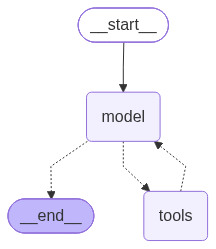

In [9]:
show_graph(agent)  # model <-> tools loop: the model keeps calling tools until it can answer

### Streaming

`agent.stream(..., stream_mode=...)` shows progress while the agent works:
`"updates"` emits one event per step of the loop, `"messages"` emits the answer token by token.


In [10]:
question = {"messages": [{"role": "user", "content": "What's the weather in Oslo?"}]}

print("stream_mode='updates' -> one event per step of the loop")
for chunk in agent.stream(question, stream_mode="updates"):
    for node, update in chunk.items():
        print(f"  {node:<6} -> {type(update['messages'][-1]).__name__}")

print("\nstream_mode='messages' -> token by token")
for token, metadata in agent.stream(question, stream_mode="messages"):
    if metadata["langgraph_node"] == "model" and token.content:
        print(token.content, end="", flush=True)

stream_mode='updates' -> one event per step of the loop


  model  -> AIMessage
  tools  -> ToolMessage


  model  -> AIMessage

stream_mode='messages' -> token by token


The

 weather

 in

... (4 outputs left out)

°C

 and

 cloudy

.

### Structured output

Pass `response_format=<Pydantic class>` and the agent returns a validated object in `result["structured_response"]` — useful when another program, not a human, consumes the answer.


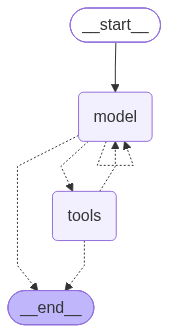

TripBrief -> city='Paris' weather='18°C, light rain' budget_usd=326.09 pack_umbrella=True


In [11]:
class TripBrief(BaseModel):
    city: str
    weather: str = Field(description="Short weather description")
    budget_usd: float | None = Field(
        default=None, description="Budget converted to USD, if one was given"
    )
    pack_umbrella: bool


brief_agent = create_agent(model, tools=tools, response_format=TripBrief)
show_graph(brief_agent)  # one extra node produces the structured response
result = brief_agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "Trip to Paris with a 300 EUR budget. Should I pack an umbrella?",
            }
        ]
    }
)
brief = result["structured_response"]
print(type(brief).__name__, "->", brief)

> **Takeaway:** `create_agent` _is_ the agent loop. Everything else in this notebook (memory, middleware, MCP tools; human review has its own notebook) is just another argument.


## 3. Short-term memory: checkpointer + `thread_id`

An agent is **stateless** by default: every `invoke` starts from a blank conversation. Give `create_agent` a **checkpointer** and pass a `thread_id` in the call config — LangGraph saves the state after every step and reloads it for the same thread.

- `InMemorySaver` lives in RAM, ideal for notebooks (it is the same class as `MemorySaver`, which you will see in the next course). In production use a database-backed saver (SQLite, Postgres).
- A different `thread_id` is a separate conversation — typically one per user or chat session.


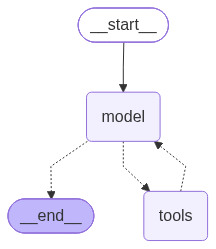

alice: Hi Alice! That sounds exciting! Do you need any information or assistance regarding your trip to Oslo?


alice: You're flying to Oslo, which is the capital city of Norway. If you need any information about Oslo, such as weather, attractions, or travel tips, feel free to ask!


bob:   I don't have access to your flight information. Could you please provide the name of the city you are flying to?


In [12]:
memory_agent = create_agent(model, tools=tools, checkpointer=InMemorySaver())
show_graph(memory_agent)  # same shape: a checkpointer saves state, it is not a node

alice = {"configurable": {"thread_id": "alice"}}
bob = {"configurable": {"thread_id": "bob"}}


def say(text, thread):
    reply = memory_agent.invoke(
        {"messages": [{"role": "user", "content": text}]}, thread
    )
    return reply["messages"][-1].content


print("alice:", say("Hi, I'm Alice and I'm flying to Oslo next week.", alice))
print("alice:", say("Which city am I flying to?", alice))
print("bob:  ", say("Which city am I flying to?", bob))

In [13]:
snapshot = memory_agent.get_state(alice)
print("messages stored for alice  :", len(snapshot.values["messages"]))
print("checkpoints saved for alice:", len(list(memory_agent.get_state_history(alice))))

messages stored for alice  : 4
checkpoints saved for alice: 6


> **Takeaway:** memory = `checkpointer=` + `thread_id`. The stored history is also what makes pausing/resuming (see the human-in-the-loop notebook) possible. Histories grow, though — middleware (next) can shrink them.


## 4. Middleware — hooks around the agent loop

The loop from section 2 is fixed, but real applications need to _change_ it: tailor the prompt, log tool calls, hide PII, shrink long chats, survive a model outage. **Middleware** does that without editing graph nodes.

```text
 before_agent                                                   after_agent
      │                                                             ▲
      ▼                                                             │
┌───────────── loop (repeats while the model asks for tools) ──────────────┐
│  before_model ─▶ wrap_model_call( MODEL ) ─▶ after_model                 │
│                          │  tool calls?                                  │
│                          ▼                                               │
│                 wrap_tool_call( TOOLS ) ─▶ back to before_model          │
└──────────────────────────────────────────────────────────────────────────┘
```

| Hook                                  | Runs                   | Typical use                                    |
| ------------------------------------- | ---------------------- | ---------------------------------------------- |
| `before_agent` / `after_agent`        | once per run           | input checks, auditing, final answer checks    |
| `before_model` / `after_model`        | around each model step | trim or summarize history, redact PII          |
| `wrap_model_call` / `@dynamic_prompt` | around each model call | change prompt, model or tools; retry; fallback |
| `wrap_tool_call`                      | around each tool call  | logging, retries, caching, blocking            |

Write your own with **decorators** (one hook) or an **`AgentMiddleware` subclass** (several hooks). Order matters: `before_*` hooks run first-to-last, `after_*` hooks last-to-first, and `wrap_*` hooks nest (the first in the list is outermost).

### 4.1 Custom middleware with decorators


In [14]:
@dataclass
class UserContext:
    role: str  # per-call data that is not part of the chat history


@dynamic_prompt
def role_based_prompt(request: ModelRequest) -> str:
    style = (
        "in simple words a child understands"
        if request.runtime.context.role == "child"
        else "in a professional tone"
    )
    return f"You are a travel assistant. Answer in one sentence, {style}."


@wrap_tool_call
def log_tool_calls(request, handler):
    print(f"   [tool ] {request.tool_call['name']}({request.tool_call['args']})")
    return handler(request)  # run the real tool


@before_model
def count_messages(state: AgentState, runtime):
    print(f"   [model] sending {len(state['messages'])} message(s) to the model")


custom_agent = create_agent(
    model,
    tools=tools,
    middleware=[role_based_prompt, log_tool_calls, count_messages],
    context_schema=UserContext,
)

for role in ("child", "professional"):
    print(f"--- role = {role}")
    out = custom_agent.invoke(
        {"messages": [{"role": "user", "content": "What's the weather in Oslo?"}]},
        context=UserContext(role=role),
    )
    print("   answer:", out["messages"][-1].content)

--- role = child
   [model] sending 1 message(s) to the model


   [tool ] get_weather({'city': 'Oslo'})
   [model] sending 3 message(s) to the model


   answer: The weather in Oslo is 7 degrees Celsius and cloudy.
--- role = professional
   [model] sending 1 message(s) to the model


   [tool ] get_weather({'city': 'Oslo'})
   [model] sending 3 message(s) to the model


   answer: The weather in Oslo is currently 7°C and cloudy.


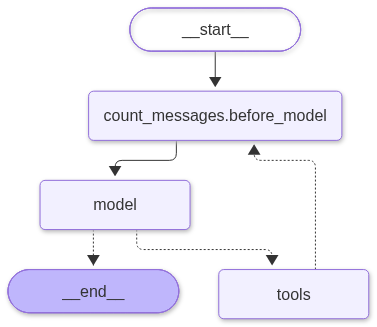

In [15]:
show_graph(custom_agent)  # every middleware hook became its own node

The class form groups several hooks in one object (handy for reusable middleware you share across projects):


In [16]:
class AuditTrail(AgentMiddleware):
    def before_agent(self, state, runtime):
        print(f"   [audit] request : {state['messages'][-1].content}")

    def after_agent(self, state, runtime):
        print(f"   [audit] response: {state['messages'][-1].content}")


audited_agent = create_agent(model, tools=tools, middleware=[AuditTrail()])
_ = audited_agent.invoke(
    {"messages": [{"role": "user", "content": "What's the weather in Paris?"}]}
)

   [audit] request : What's the weather in Paris?


   [audit] response: The weather in Paris is currently 18°C with light rain.


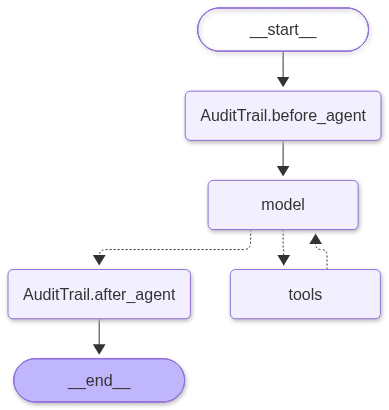

In [17]:
show_graph(audited_agent)  # every middleware hook became its own node

### 4.2 Built-in middleware

You do not have to write everything yourself. Three useful ones, each a few lines:

**`PIIMiddleware`** — detect and `redact` / `mask` / `hash` / `block` sensitive data _before_ it reaches the model (in week 9 you built this by hand with Presidio):


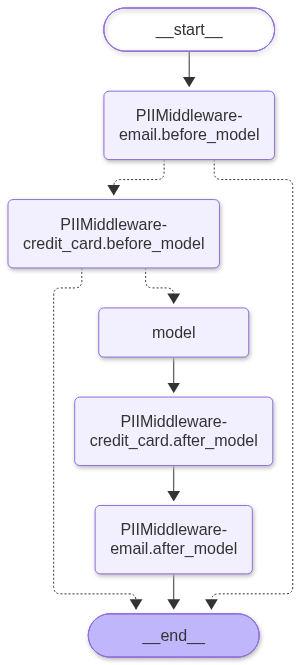

The model saw : My email is [REDACTED_EMAIL] and my card is **** **** **** 1111. Which details did I just give you?
The model said: You provided an email address (which has been redacted) and the last four digits of a credit card number (1111). However, for your privacy and security, it's important not to share sensitive information like email addresses or credit card details in public forums.


In [18]:
pii_agent = create_agent(
    model,
    tools=[],
    middleware=[
        PIIMiddleware("email", strategy="redact"),
        PIIMiddleware("credit_card", strategy="mask"),
    ],
)
show_graph(pii_agent)  # no tools, but the PII hooks appear as nodes
out = pii_agent.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": "My email is john.doe@example.com and my card is 4111 1111 1111 1111. Which details did I just give you?",
            }
        ]
    }
)
print("The model saw :", out["messages"][0].content)
print("The model said:", out["messages"][-1].content)

**`SummarizationMiddleware`** — long chats overflow the context window. Once a threshold is reached, old messages are replaced by a summary. (Tiny thresholds here so you can see it happen.)


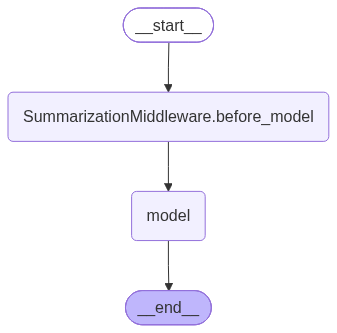

history = 2 messages | My name is Priya and I love chess. -> Hi Priya! It's great to meet a fellow chess enthusiast. What do you en


history = 4 messages | I live in Lisbon. -> Lisbon is a beautiful city with a rich history and vibrant culture! Do


history = 6 messages | I work as a nurse. -> That's a noble profession, Priya! Nurses play such a vital role in hea


history = 4 messages | What is 2 + 2? -> 2 + 2 equals 4. If you have any other questions or topics you'd like t


history = 6 messages | What do you remember about me? -> I remember that your name is Priya, and you live in Lisbon. You work a

First message the model now sees:
 Here is a summary of the conversation to date:

## SESSION INTENT
The user's primary goal is to engage in a conversation about chess and share personal information, including their location and profession.

## SUMMARY
The user, Priya, loves chess and ...


In [19]:
summary_agent = create_agent(
    model,
    tools=[],
    middleware=[
        SummarizationMiddleware(
            model=model, trigger=("messages", 6), keep=("messages", 2)
        )
    ],
    checkpointer=InMemorySaver(),
)
show_graph(summary_agent)
thread = {"configurable": {"thread_id": "long-chat"}}

for text in [
    "My name is Priya and I love chess.",
    "I live in Lisbon.",
    "I work as a nurse.",
    "What is 2 + 2?",
    "What do you remember about me?",
]:
    out = summary_agent.invoke(
        {"messages": [{"role": "user", "content": text}]}, thread
    )
    print(
        f"history = {len(out['messages'])} messages | {text} -> {out['messages'][-1].content[:70]}"
    )

print("\nFirst message the model now sees:\n", out["messages"][0].content[:250], "...")

**`ModelFallbackMiddleware`** — if the primary model fails (outage, rate limit), try the next one. Here the primary model name is deliberately wrong:


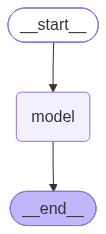

Fallback worked!


In [20]:
broken_primary = init_chat_model("openai:this-model-does-not-exist")
resilient_agent = create_agent(
    broken_primary,
    tools=[],
    middleware=[ModelFallbackMiddleware("openai:gpt-4o-mini")],
)
show_graph(resilient_agent)
print(
    resilient_agent.invoke(
        {"messages": [{"role": "user", "content": "Say: fallback worked"}]}
    )["messages"][-1].content
)

Other built-ins worth knowing (see the docs for the full list):

| Middleware                                            | Purpose                                                       |
| ----------------------------------------------------- | ------------------------------------------------------------- |
| `ModelCallLimitMiddleware`, `ToolCallLimitMiddleware` | budgets that stop runaway loops (used in the week 8 LexAgent) |
| `ModelRetryMiddleware`, `ToolRetryMiddleware`         | retry transient failures with backoff                         |
| `TodoListMiddleware`                                  | gives the agent a planning to-do list                         |
| `LLMToolSelectorMiddleware`                           | picks only the relevant tools when you have dozens            |
| `ContextEditingMiddleware`                            | clears old tool outputs to save tokens                        |
| `HumanInTheLoopMiddleware` | pauses for human review — see `W10_Human_in_the_Loop.ipynb` |

> **Takeaway:** behaviour that must _always_ hold (privacy, budgets, review) belongs in middleware, not in a prompt the model may ignore.


## 5. Using outside MCP servers

In weeks 7–9 you **built** MCP servers. The real value of MCP is the opposite direction: **reuse servers other people already built**, with no server code at all.

| Transport                | Where the server runs                 | Config                                                  | Example                                             |
| ------------------------ | ------------------------------------- | ------------------------------------------------------- | --------------------------------------------------- |
| `http` (streamable HTTP) | remote, hosted by someone else        | `{"transport": "http", "url": ...}`                     | the LangChain docs server                           |
| `stdio`                  | a local subprocess your client starts | `{"transport": "stdio", "command": ..., "args": [...]}` | the official filesystem server, launched with `npx` |

Where to find servers: the [official MCP Registry](https://registry.modelcontextprotocol.io), the [modelcontextprotocol/servers](https://github.com/modelcontextprotocol/servers) repository, and vendors that publish their own (GitHub, Notion, Stripe, …).

`MultiServerMCPClient` connects to several servers at once and returns their tools as ordinary LangChain tools. We use one remote and one local server.


In [21]:
sandbox = Path(
    tempfile.mkdtemp(prefix="mcp_demo_")
)  # the only folder the local server may touch
(sandbox / "notes.txt").write_text(
    "Week 10 notes: MCP lets an agent use tools it did not ship with. Questions? Email prof.smith@example.edu"
)

servers = {
    # remote server over HTTP: nothing to install or run
    "langchain_docs": {"transport": "http", "url": "https://docs.langchain.com/mcp"},
    # a second remote server, from a travel company: real flight search, no API key needed
    "kiwi": {"transport": "http", "url": "https://mcp.kiwi.com"},
}
if shutil.which("npx"):
    # local server started as a subprocess (stdio): an official reference server
    servers["files"] = {
        "transport": "stdio",
        "command": "npx",
        "args": ["-y", "@modelcontextprotocol/server-filesystem", str(sandbox)],
    }
else:
    print(
        "npx not found: install Node.js to try the local (stdio) server. Continuing with the remote one only."
    )
HAS_FILES = "files" in servers

mcp_client = MultiServerMCPClient(servers)
all_tools = []
for server_name in servers:
    try:
        server_tools = await mcp_client.get_tools(server_name=server_name)
    except Exception as error:  # a third-party server can be down: keep going with the others
        print(f"\n{server_name}: unavailable ({type(error).__name__})")
        continue
    all_tools += server_tools
    print(f"\n{server_name}: {len(server_tools)} tools")
    for t in server_tools:
        print(f"  - {t.name}")


langchain_docs: 3 tools
  - search_docs_by_lang_chain
  - query_docs_filesystem_docs_by_lang_chain
  - submit_feedback



kiwi: 2 tools
  - search-flight
  - feedback-to-devs



files: 14 tools
  - read_file
  - read_text_file
  - read_media_file
  - read_multiple_files
  - write_file
  - edit_file
  - create_directory
  - list_directory
  - list_directory_with_sizes
  - directory_tree
  - move_file
  - search_files
  - get_file_info
  - list_allowed_directories


**Second example: the Kiwi.com flight-search server.** A travel company publishes its own MCP server at `https://mcp.kiwi.com` (streamable HTTP, no key). It offers `search-flight` (live one-way or return flights) and `feedback-to-devs`. This is the pattern you will see more and more: *a company exposes its product as MCP tools and any agent can use them*. Notice that we configured it with a single URL.

### Give the agent only what it needs

The filesystem server also exposes `write_file`, `edit_file` and `move_file`. An agent should not get a tool it does not need — filter the list by name (**least privilege**). The same goes for Kiwi: we keep `search-flight` and leave out `feedback-to-devs`, a tool that would send text from our conversation to a third party.


In [22]:
ALLOWED = {"search_docs_by_lang_chain", "search-flight", "list_directory", "read_text_file"}
read_only_tools = [t for t in all_tools if t.name in ALLOWED]
print(
    f"{len(all_tools)} tools exposed by the servers -> {len(read_only_tools)} given to the agent:"
)
print([t.name for t in read_only_tools])

19 tools exposed by the servers -> 4 given to the agent:
['search_docs_by_lang_chain', 'search-flight', 'read_text_file', 'list_directory']


MCP tools are asynchronous, so the agent is called with `await agent.ainvoke(...)` (top-level `await` works in a notebook cell). Flight prices are live, so your numbers will differ from run to run.


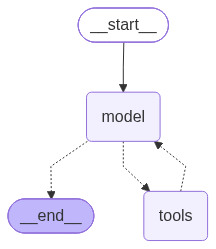

Q: What does notes.txt in /tmp/mcp_demo__8f5yqjt say?
   tools used: ['read_text_file']
   A: The notes in `notes.txt` state: "Week 10 notes: MCP lets an agent use tools it did not ship with. Questions? Email prof.smith@example.edu."



Q: Using the LangChain docs, what is middleware in a LangChain agent?
   tools used: ['search_docs_by_lang_chain']
   A: In LangChain, middleware allows customization of agent behavior by hooking into model calls, tool calls, and agent lifecycle events. Middleware classes extend the `AgentMiddleware` base class and can be used for various purposes, such as implementing guardrails, logging, or modifying inputs and outputs. There are two main types of middleware: provider-specific, which leverages unique capabilities of a provider, and cross-provider, which works with any model or tool.



Q: What is the cheapest one-way flight from Prague to Lisbon on 2026-12-15 for 1 adult? Give airline route, price and duration.
   tools used: ['search-flight']
   A: The cheapest one-way flight from Prague to Lisbon on December 15, 2026, is as follows:

- **Route**: Prague (PRG) → Milan (BGY) → Lisbon (LIS)
- **Price**: 101 EUR
- **Duration**: 9 hours and 20 minutes (including a layover)

You can book it [here](https://kiwi.com/u/jcwzsx).



In [23]:
mcp_agent = create_agent(
    model,
    tools=read_only_tools,
    system_prompt="Answer using the tools. At most three short sentences.",
)

show_graph(mcp_agent)

questions = [
    "Using the LangChain docs, what is middleware in a LangChain agent?",
    "What is the cheapest one-way flight from Prague to Lisbon on 2026-12-15 for 1 adult? Give airline route, price and duration.",
]
if HAS_FILES:
    questions.insert(0, f"What does notes.txt in {sandbox} say?")

for question in questions:
    out = await mcp_agent.ainvoke({"messages": [{"role": "user", "content": question}]})
    used = [
        call["name"] for m in out["messages"] if m.type == "ai" for call in m.tool_calls
    ]
    print(
        f"Q: {question}\n   tools used: {used}\n   A: {out['messages'][-1].content}\n"
    )

**Servers that need authentication** pass headers in the same config (shown, not executed — it needs your own token):

```python
MultiServerMCPClient({
    "github": {
        "transport": "http",
        "url": "https://api.githubcopilot.com/mcp/",
        "headers": {"Authorization": f"Bearer {os.environ['GITHUB_TOKEN']}"},
    }
})
```

**Security checklist before plugging in a third-party server** (this is the week 8–9 responsible-AI mindset applied to tools):

- **Trust:** a server's tool descriptions and results go straight into your model's context, so a malicious or compromised server can inject instructions.
- **Least privilege:** allow-list tools by name (above) and scope what a server can reach (here: one temp folder).
- **Pin versions:** `npx -y pkg@1.2.3` instead of whatever is latest.
- **Review side effects:** combine with `HumanInTheLoopMiddleware` (see `W10_Human_in_the_Loop.ipynb`) for tools that write or send.
- **Sanitize:** middleware such as `PIIMiddleware(..., apply_to_tool_results=True)` also covers what tools return.
- **Statelessness:** by default each tool call opens a fresh session; use `client.session("name")` when a server must keep state between calls.


## 6. Putting it together

One agent, three ideas from this notebook: **MCP tools** (read and write files), **middleware** (`PIIMiddleware` also applied to tool results) and **memory** (checkpointer + `thread_id`, so a follow-up question works). Notice how little code that is.

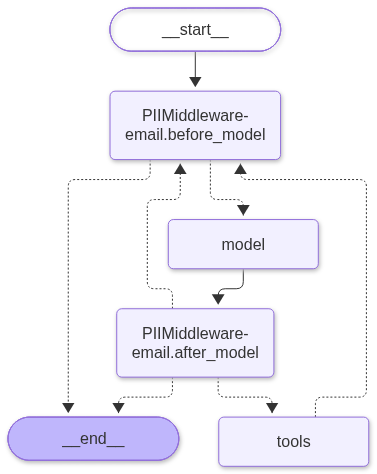

Agent: The summary has been saved to `/tmp/mcp_demo__8f5yqjt/summary.txt`.

summary.txt on disk: Week 10 notes: MCP lets an agent use tools it did not ship with. Questions? Email [REDACTED_EMAIL]
(notes.txt contains a real email address, but the middleware redacted it from the tool result, so the model never saw it.)



Follow-up: I created the file `/tmp/mcp_demo__8f5yqjt/summary.txt`.


In [24]:
if not HAS_FILES:
    print("Skipped: this demo needs the local filesystem MCP server (install Node.js and re-run section 5).")
else:
    wanted = {"list_directory", "read_text_file", "write_file"}
    team_tools = [t for t in await mcp_client.get_tools(server_name="files") if t.name in wanted]

    assistant = create_agent(
        model,
        tools=team_tools,
        system_prompt="You are a note-taking assistant. Be brief.",
        middleware=[PIIMiddleware("email", strategy="redact", apply_to_tool_results=True)],
        checkpointer=InMemorySaver(),
    )
    show_graph(assistant)

    config = {"configurable": {"thread_id": "notes-demo"}}
    task = f"Read {sandbox}/notes.txt, then save a one-line summary that includes the contact email to {sandbox}/summary.txt."
    result = await assistant.ainvoke({"messages": [{"role": "user", "content": task}]}, config)
    print("Agent:", result["messages"][-1].content)
    print("\nsummary.txt on disk:", (sandbox / "summary.txt").read_text())
    print("(notes.txt contains a real email address, but the middleware redacted it from the tool result, so the model never saw it.)")

    # memory: the follow-up question only works because of the checkpointer + thread_id
    follow_up = await assistant.ainvoke({"messages": [{"role": "user", "content": "Which file did you just create?"}]}, config)
    print("\nFollow-up:", follow_up["messages"][-1].content)

In [25]:
shutil.rmtree(sandbox, ignore_errors=True)  # clean up the temporary folder

## 7. Recap and where to go next

| You want to…                                                          | Reach for                                                      |
| --------------------------------------------------------------------- | -------------------------------------------------------------- |
| Build a standard tool-calling agent quickly | `create_agent(model, tools, system_prompt=...)`; draw it with `agent.get_graph()` |
| Get a typed answer for downstream code                                | `response_format=PydanticModel`                                |
| Remember a conversation                                               | `checkpointer=InMemorySaver()` + `thread_id`                   |
| Add privacy, budgets, retries, fallbacks, summaries, custom behaviour | `middleware=[...]`                                             |
| Have a person approve risky actions | `HumanInTheLoopMiddleware` + checkpointer (next notebook: `W10_Human_in_the_Loop.ipynb`) |
| Use tools somebody else built | `MultiServerMCPClient` (`http` or `stdio`) + a tool allow-list (e.g. LangChain docs, Kiwi flights) |

**Go further**

- **Observability:** set `LANGSMITH_TRACING=true` and `LANGSMITH_API_KEY` to see every model call, tool call and middleware step as a trace. Add both to your `.env` file (or Colab secrets) and they are picked up automatically.
- **Custom graphs:** when the flow is no longer "model ↔ tools" (branching, multiple agents), drop down to LangGraph `StateGraph`, as in weeks 7–9. `create_agent` and hand-built graphs combine well.
- **Agent-to-agent communication:** coming up in the next course.

**References (LangChain docs):**
[Agents](https://docs.langchain.com/oss/python/langchain/agents) ·
[Structured output](https://docs.langchain.com/oss/python/langchain/structured-output) ·
[Streaming](https://docs.langchain.com/oss/python/langchain/streaming) ·
[Short-term memory](https://docs.langchain.com/oss/python/langchain/short-term-memory) ·
[Middleware overview](https://docs.langchain.com/oss/python/langchain/middleware/overview) ·
[Built-in middleware](https://docs.langchain.com/oss/python/langchain/middleware/built-in) ·
[Custom middleware](https://docs.langchain.com/oss/python/langchain/middleware/custom) ·
[Human-in-the-loop](https://docs.langchain.com/oss/python/langchain/human-in-the-loop) ·
[MCP](https://docs.langchain.com/oss/python/langchain/mcp)

_Topics inspired by LangChain Academy material (models, tools, MCP, threads/checkpointers, human-in-the-loop), adapted to the plain `create_agent` API._
